# XSeedFlow side project - sparse-view X-ray study on wheat kernels

Inspired by the Angers/LARIS-CEA internship question: *which X-ray views of a seed carry complementary information, and how far can the number of views be reduced without losing what the biologist needs?*

**Data:** the small kernel subset prepared in Step 0 (stored on Drive). **Compute:** everything runs on the GPU with plain PyTorch (no ASTRA install), sized for a free Colab T4 (about 12 GB GPU, 12 GB RAM).

| Question | What is measured |
|---|---|
| **RQ1** how many views are needed? | NRMSE / SSIM vs number of views (SIRT and FBP) |
| **RQ2** are some angles more informative? | uniform vs random vs greedy "oracle" angle selection, same view budget |
| **RQ3** does it depend on seed shape? | reconstruction error vs shape descriptors |
| **RQ4** are biological measurements preserved? | length / width / thickness / volume error vs views |
| **RQ5** is it robust? | detector noise and a rotation-centre offset |
| **RQ6** (exploratory) can shape predict the needed views? | leave-one-out regression, only if enough kernels |

**Simulation design (read this before quoting results).** The kernel's long axis is the stack axis, so every axial slice is an independent 2-D parallel-beam problem: the "views" are rotations around the kernel's long axis. Projections are simulated from already reconstructed CT slices (not from the scanner's raw physics), by the same operator that is later inverted, so absolute errors are optimistic ("inverse crime"). Comparisons between strategies on the same operator remain meaningful. Greedy selection uses the reference volume (oracle) and is not a deployable scanner policy.

Every experiment block is checkpointed to `results/results.csv` on Drive, so a disconnected session resumes where it stopped (after a reconnect, simply re-run all cells: finished blocks are skipped).

**Outputs on Drive:** `results/` (csv + figures + summary.json), `web/` (importable `xseedflow_core.py`, per-kernel 3-D meshes and volumes, precomputed reconstructions, `manifest.json` with the website's UI parameter schema) and `report/xseedflow_report.html` (self-contained interactive results page).

In [2]:
# ============ 1. SETUP, CONFIG, DATA INDEX ============
import os, re, json, time, math, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn.functional as F
from scipy import ndimage as ndi
from scipy.stats import spearmanr
from skimage.filters import threshold_otsu
from skimage.metrics import structural_similarity
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

ROOT = os.environ.get("XSF_ROOT", "/content/drive/MyDrive/XSeedFlow")
if not os.environ.get("XSF_ROOT"):
    from google.colab import drive; drive.mount("/content/drive")

# ---- config (edit here, then re-run from this cell) ----
POOL          = 2                      # extra downsampling of the stored volume (1 = stored size, 2 = 8x fewer voxels)
VIEW_COUNTS   = [4, 8, 16, 32, 64, 180]
SIRT_ITERS    = 60
TOL_PCT       = 5.0                    # tolerance (%) on length/width/thickness/volume for RQ4
NRMSE_TOL     = 0.10                   # absolute NRMSE target for RQ1
BUDGETS       = [8, 16]                # RQ2/RQ5 view budgets
N_RANDOM      = 8                      # random angle draws per kernel and budget
GREEDY_STEP   = 5                        # candidate angles every 5 degrees for greedy selection
GREEDY_SLICES = 8
GREEDY_ITERS  = 30
N_RQ2_KERNELS = 6                      # kernels used for RQ2 (greedy is the slow part)
N_RQ5_KERNELS = 4
NOISE_LEVELS  = [0.0, 0.01, 0.03, 0.05, 0.10]   # sigma relative to max of the sinogram
NOISE_SEEDS   = 3
SEED          = 0
EXPORT_N_KERNELS = 4                   # kernels exported with precomputed reconstructions for the website
DOWNLOAD_REPORT = False                # True: also trigger a browser download of the HTML report at the end

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev, torch.cuda.get_device_name(0) if dev.type == "cuda" else "(CPU: very slow, switch Runtime > T4 GPU)")
natural = lambda s: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", str(s))]
spread  = lambda lst, n: [lst[i] for i in sorted(set(np.linspace(0, len(lst) - 1, min(n, len(lst))).round().astype(int)))]

PROC = Path(ROOT) / "data" / "processed"; RES = Path(ROOT) / "results"; RES.mkdir(parents=True, exist_ok=True)
paths = {p.stem: p for p in sorted(PROC.glob("*.npz"), key=lambda p: natural(p.stem))}
KERNELS = list(paths)
print(f"{len(KERNELS)} stored kernels:", KERNELS)

# ---- morphometrics + metadata from Data.xlsx (best-effort matching Group/Sample -> kernel) ----
morph, meta_df, MATCHED = None, None, {}
xl = sorted((Path(ROOT) / "data").glob("*.xlsx"))
if xl:
    sheets = pd.read_excel(xl[0], sheet_name=None)
    morph = sheets.get("Morphometrics"); meta_df = sheets.get("Metadata")
    if meta_df is not None:
        print("\n--- Metadata sheet (look for voxel size / scan parameters) ---"); print(meta_df.to_string(index=False)[:2500])
    if morph is not None:
        morph.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in morph.columns]
        for k in KERNELS:
            g, s = re.match(r"Group(\d+)_(\w)", k).groups()
            for i, row in morph.iterrows():
                gg = re.findall(r"\d+", str(row["Group"])); ss = re.findall(r"[A-Za-z]", str(row["Sample ID"]))
                if gg and ss and int(gg[0]) == int(g) and ss[-1].lower() == s.lower():
                    MATCHED[k] = i; break
        print(f"\nmorphometrics rows matched to kernels: {len(MATCHED)}/{len(KERNELS)}")
        if MATCHED: print(morph.loc[list(MATCHED.values())].assign(kernel=list(MATCHED)).iloc[:, [-1, 2, 3, 4, 6, 7, 8]].head(8).to_string(index=False))
else:
    print("Data.xlsx not found under", Path(ROOT) / "data", "- continuing with descriptors computed from the volumes only")

Mounted at /content/drive
device: cuda Tesla T4
12 stored kernels: ['Group1_a', 'Group2_e', 'Group4_d', 'Group6_c', 'Group8_b', 'Group10_a', 'Group11_e', 'Group13_d', 'Group15_c', 'Group17_b', 'Group19_a', 'Group20_e']

--- Metadata sheet (look for voxel size / scan parameters) ---
           Category                            Parameter                                  Value                    Notes
Plant and Treatment                              Species                      Triticum aestivum                      NaN
                NaN                             Cultivar                               Jimai 22                      NaN
                NaN                               Origin                  Northern Anhui, China                      NaN
                NaN                         Harvest date                     Data not available                      NaN
                NaN              Treatment date (drying)                    2025-07-20 00:00:00                 

In [3]:
# ============ 2. CORE LIBRARY (also written to Drive as web/xseedflow_core.py for the future website backend) ============
CORE_SRC = r"""
import math, json
import numpy as np, torch, torch.nn.functional as F
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu
from skimage.metrics import structural_similarity

# settings are taken from the notebook when exec'd there, or from these defaults when imported as a module
dev           = globals().get("dev") or torch.device("cuda" if torch.cuda.is_available() else "cpu")
POOL          = globals().get("POOL", 2)
SIRT_ITERS    = globals().get("SIRT_ITERS", 60)
GREEDY_STEP   = globals().get("GREEDY_STEP", 5)
GREEDY_SLICES = globals().get("GREEDY_SLICES", 8)
GREEDY_ITERS  = globals().get("GREEDY_ITERS", 30)
paths         = globals().get("paths", {})          # kernel name -> .npz file produced by Step 0

class Lib:
    # parallel-beam geometry for SxS slices; angle library = 0..179 degrees in 1-degree steps
    def __init__(self, S):
        self.S = S
        t = torch.deg2rad(torch.arange(180, dtype=torch.float32, device=dev))
        c, s, z = torch.cos(t), torch.sin(t), torch.zeros_like(t)
        th  = torch.stack([torch.stack([c, -s, z], -1), torch.stack([s, c, z], -1)], -2)
        thi = torch.stack([torch.stack([c, s, z], -1), torch.stack([-s, c, z], -1)], -2)
        self.G  = F.affine_grid(th,  (180, 1, S, S), align_corners=False)
        self.Gi = F.affine_grid(thi, (180, 1, S, S), align_corners=False)
        yy, xx = torch.meshgrid(torch.arange(S, device=dev), torch.arange(S, device=dev), indexing="ij")
        self.disc = ((yy - (S - 1) / 2) ** 2 + (xx - (S - 1) / 2) ** 2) <= (S / 2) ** 2
_libs = {}
def get_lib(S):
    if S not in _libs: _libs[S] = Lib(S)
    return _libs[S]

@torch.no_grad()
def fp(x, lib, idx=None):
    # forward projection of slices x (B,S,S) -> sinogram (B,A,S); idx = angle indices in 0..179 (default: all)
    idx = np.arange(180) if idx is None else np.asarray(idx)
    B, S = x.shape[0], x.shape[-1]; xs = x[:, None]; out = torch.empty(B, len(idx), S, device=x.device)
    for j, a in enumerate(idx):
        out[:, j] = F.grid_sample(xs, lib.G[a:a + 1].expand(B, -1, -1, -1), align_corners=False)[:, 0].sum(1)
    return out

@torch.no_grad()
def bp(sino, lib, idx):
    B, A, S = sino.shape; out = torch.zeros(B, S, S, device=sino.device)
    for j, a in enumerate(idx):
        sm = sino[:, j][:, None, None, :].expand(B, 1, S, S)
        out += F.grid_sample(sm, lib.Gi[a:a + 1].expand(B, -1, -1, -1), align_corners=False)[:, 0]
    return out

@torch.no_grad()
def fbp(sino, lib, idx):
    # filtered back-projection (Ram-Lak); only valid for angles uniformly covering [0,180)
    B, A, S = sino.shape; P = 2 * S
    filt = torch.fft.rfftfreq(P, device=sino.device).abs()
    q = torch.fft.irfft(torch.fft.rfft(sino, n=P, dim=-1) * filt, n=P, dim=-1)[..., :S]
    return (bp(q, lib, idx) * math.pi / A) * lib.disc

@torch.no_grad()
def sirt(sino, lib, idx, iters=None, lo=0.0, hi=1.0):
    # SIRT with box constraint [lo,hi] (volumes are normalised to [0,1])
    iters = SIRT_ITERS if iters is None else iters
    B, A, S = sino.shape; idx = np.asarray(idx); d = lib.disc
    R = 1.0 / fp(d[None].float(), lib, idx).clamp_min(1.0)
    C = 1.0 / bp(torch.ones(1, A, S, device=sino.device), lib, idx).clamp_min(0.5)
    x = torch.zeros(B, S, S, device=sino.device)
    for _ in range(iters):
        x = ((x + C * bp((sino - fp(x, lib, idx)) * R, lib, idx)).clamp_(lo, hi)) * d
    return x

def reconstruct(sino_sub, lib, idx, method="sirt", iters=None):
    return fbp(sino_sub, lib, idx) if method == "fbp" else sirt(sino_sub, lib, idx, iters)

def largest_cc(m):
    lab, n = ndi.label(m)
    return m if n <= 1 else lab == (1 + int(np.argmax(ndi.sum(m, lab, range(1, n + 1)))))

def measure(mask):
    # volume (voxels) + extent along the 3 principal axes (voxels): L >= W >= T
    p = np.argwhere(mask).astype(np.float32)
    if len(p) < 50: return dict(vol=np.nan, L=np.nan, W=np.nan, T=np.nan)
    p -= p.mean(0); w, V = np.linalg.eigh(np.cov(p.T)); pr = p @ V[:, np.argsort(w)[::-1]]
    e = pr.max(0) - pr.min(0) + 1
    return dict(vol=float(len(p)), L=float(e[0]), W=float(e[1]), T=float(e[2]))

def load_ref(name):
    d = np.load(paths[name]); raw = d["volume"]
    v = raw.astype(np.float32) / (255.0 if raw.dtype == np.uint8 else 65535.0)
    r = max(1, int(round(float(d["xy_downsample"]) / float(d["z_stride"]))))   # stored z is r times finer than x,y
    pz, pxy = POOL * r, POOL
    z, y, x = [(n // p) * p for n, p in zip(v.shape, (pz, pxy, pxy))]
    v = v[:z, :y, :x].reshape(z // pz, pz, y // pxy, pxy, x // pxy, pxy).mean((1, 3, 5))
    S = max(v.shape[1:]); S += S % 2
    v = np.pad(v, ((0, 0), (0, S - v.shape[1]), (0, S - v.shape[2])), mode="edge")
    t0_ = threshold_otsu(v[::3, ::2, ::2]); bg = float(v[v < t0_].mean()); hi = float(np.percentile(v, 99.9))
    v = np.clip((v - bg) / max(hi - bg, 1e-6), 0, 1).astype(np.float32)          # air -> 0, as in attenuation relative to air
    lib = get_lib(S); g = torch.from_numpy(v).to(dev)
    thr = float(threshold_otsu(v[::3, ::2, ::2])); m0 = (g > thr).cpu().numpy()
    out_frac = float((m0 & ~lib.disc.cpu().numpy()[None]).sum() / max(m0.sum(), 1)); g = g * lib.disc
    mask = largest_cc((g > thr).cpu().numpy()); m = measure(mask)
    zs = np.where(mask.any((1, 2)))[0]
    return dict(name=name, gpu=g, lib=lib, S=S, thr=thr, mask=mask, m=m, rng=float(g.max() - g.min()), out_frac=out_frac,
                sino_max=float(fp(g, lib).max()), zs=zs, ssim_idx=zs[np.linspace(0, len(zs) - 1, 12).astype(int)], shape=tuple(g.shape))

_refs = {}
def get_ref(k):
    if k not in _refs: _refs[k] = load_ref(k)
    return _refs[k]

def nrmse_t(rec, ref, lib, rng):
    return float(((rec - ref) ** 2)[:, lib.disc].mean().sqrt() / rng)

def evaluate(R, rec, thr_scale=1.0, full=False):
    # image metrics (NRMSE, SSIM) + task metrics (% error of volume / length / width / thickness after thresholding)
    out = dict(nrmse=nrmse_t(rec, R["gpu"], R["lib"], R["rng"]))
    a = rec[R["ssim_idx"]].cpu().numpy(); b = R["gpu"][R["ssim_idx"]].cpu().numpy()
    out["ssim"] = float(np.mean([structural_similarity(x, y, data_range=1.0) for x, y in zip(a, b)]))
    thr = R["thr"] * thr_scale
    if thr_scale == 1.0: rmask, rm = R["mask"], R["m"]
    else: rmask = largest_cc((R["gpu"] > thr).cpu().numpy()); rm = measure(rmask)
    mk = largest_cc((rec > thr).cpu().numpy()); m = measure(mk)
    for q in ("vol", "L", "W", "T"):
        out[q + "_err"] = 100.0 * (m[q] - rm[q]) / rm[q]
        if full: out[q + "_rec"], out[q + "_ref"] = m[q], rm[q]
    out["dice"] = float(2 * (mk & rmask).sum() / max(mk.sum() + rmask.sum(), 1))
    return out

unif_idx = lambda K: np.round(np.linspace(0, 180, K, endpoint=False)).astype(int)

def greedy_select(R, K_max, step=None, nsl=None, iters=None):
    # oracle greedy angle selection on a few reference slices (uses the reference volume: not a deployable policy)
    step = step or GREEDY_STEP; nsl = nsl or GREEDY_SLICES; iters = iters or GREEDY_ITERS
    cand = np.arange(0, 180, step)
    assert K_max <= len(cand), "lower GREEDY_STEP or reduce the view budget"
    lib = R["lib"]; zs = R["zs"]; sel = zs[np.linspace(0, len(zs) - 1, nsl).astype(int)]
    x = R["gpu"][sel]; sino = fp(x, lib); chosen, traj = [], []
    for _ in range(K_max):
        best = (1e9, None)
        for c in cand:
            if c in chosen: continue
            idx = np.array(sorted(chosen + [int(c)]))
            e = nrmse_t(sirt(sino[:, idx], lib, idx, iters), x, lib, R["rng"])
            if e < best[0]: best = (e, int(c))
        chosen.append(best[1]); traj.append(best[0])
    return chosen, traj

def run_scenario(R, angles, method="sirt", iters=None, noise=0.0, cor_shift=0, seed=0, thr_scale=1.0, full=False):
    # ONE call = one website interaction: choose angles -> simulate projections (+noise, +rotation-centre offset) -> reconstruct -> metrics
    idx = np.array(sorted(set(int(a) % 180 for a in angles)))
    sino = fp(R["gpu"], R["lib"], idx)
    if cor_shift: sino = torch.roll(sino, int(cor_shift), dims=-1)
    if noise > 0:
        g_ = torch.Generator(device=dev).manual_seed(int(seed))
        sino = sino + noise * R["sino_max"] * torch.randn(sino.shape, device=dev, generator=g_)
    rec = reconstruct(sino, R["lib"], idx, method, iters)
    return rec, evaluate(R, rec, thr_scale, full)

def mesh_from_volume(vol, level, step=1):
    # triangle surface (vertices in z,y,x voxel units) of a (z,y,x) volume at the given iso-level
    from skimage.measure import marching_cubes
    verts, faces, _, _ = marching_cubes(np.pad(np.asarray(vol, np.float32), 1), level=level, step_size=step)
    return verts - 1, faces

def surface_deviation(ref_mask, verts):
    # signed distance (voxels) of mesh vertices to the reference surface: >0 outside the reference, <0 inside
    sd = ndi.distance_transform_edt(~ref_mask) - ndi.distance_transform_edt(ref_mask)
    i = np.clip(np.round(verts).astype(int), 0, np.array(ref_mask.shape) - 1)
    return sd[i[:, 0], i[:, 1], i[:, 2]]
"""
exec(CORE_SRC, globals())
(Path(ROOT) / "web").mkdir(parents=True, exist_ok=True); (Path(ROOT) / "web" / "xseedflow_core.py").write_text(CORE_SRC)

# ---- notebook-only helpers: results store with checkpointing, shape table, voxel-size calibration ----
RESF = RES / "results.csv"
res = pd.read_csv(RESF) if RESF.exists() else pd.DataFrame()
def done(k, exp): return len(res) > 0 and bool(((res.kernel == k) & (res.exp == exp)).any())
def save_block(rows):
    global res
    res = pd.concat([res, pd.DataFrame(rows)], ignore_index=True); res.to_csv(RESF, index=False)

def shape_table():
    d = pd.DataFrame([dict(kernel=k, **{q: get_ref(k)["m"][q] for q in ("vol", "L", "W", "T")}) for k in KERNELS])
    d["elongation_L/W"] = d.L / d.W; d["cross_section_W/T"] = d.W / d["T"]; return d

def calibrate(desc):
    # mm per experiment voxel, self-calibrated from the published major-axis length of the matched kernels
    if len(MATCHED) < 3: return np.nan
    col = [c for c in morph.columns if c.lower().startswith("major")][0]
    return float(np.median([morph.loc[MATCHED[k], col] / desc.set_index("kernel").loc[k, "L"] for k in MATCHED]))
print("library ready | core exported to", Path(ROOT) / "web" / "xseedflow_core.py", "| resumed results rows:", len(res))

library ready | core exported to /content/drive/MyDrive/XSeedFlow/web/xseedflow_core.py | resumed results rows: 544


phantom check | <Ax,y>/<x,A^T y> = 1.000 (want ~1) | 90-view NRMSE: FBP 0.034, SIRT 0.040 (want small)
Group1_a: experiment volume (180, 116, 116) (z,y,x) | threshold 0.283 | kernel voxels outside the reconstruction disc: 0.05% (want ~0)
reference measurements (voxels): {'vol': 898684.0, 'L': 182.3, 'W': 108.5, 'T': 98.3}
one 16-view SIRT reconstruction: 0.6s -> RQ1 estimate ~2 min for 12 kernels
peak GPU memory: 0.13 GB


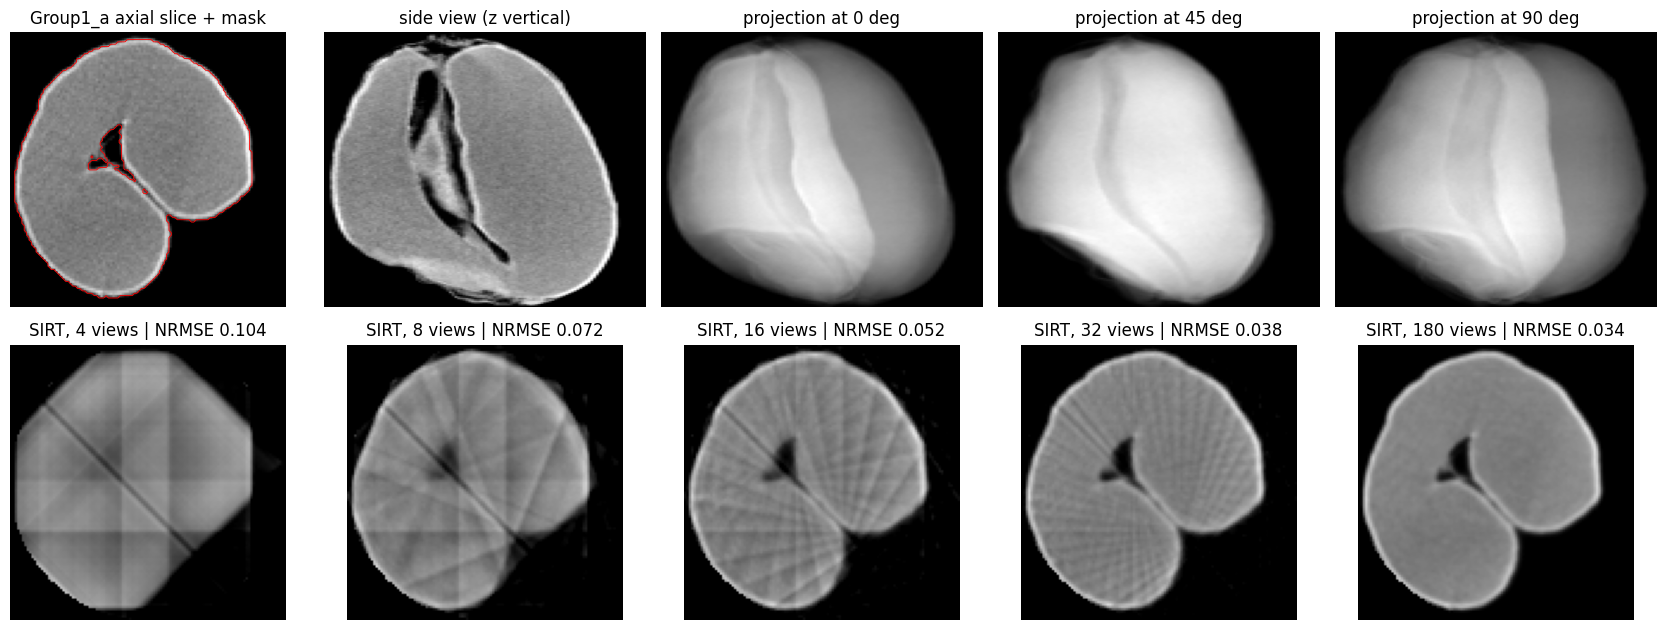

In [4]:
# ============ 3. SANITY CHECKS + FIRST LOOK (operator correctness, timing, GPU memory) ============
# (a) phantom: adjoint consistency and FBP scale
S0 = 96; lib0 = get_lib(S0); yy, xx = np.mgrid[:S0, :S0]
ph = (((yy - 44) / 26) ** 2 + ((xx - 52) / 14) ** 2 < 1).astype(np.float32) * 0.8 + (((yy - 50) / 6) ** 2 + ((xx - 45) / 6) ** 2 < 1) * 0.2
ph = torch.from_numpy(ph.astype(np.float32)).to(dev)[None] * lib0.disc
ids = np.arange(0, 180, 2); sn = fp(ph, lib0, ids); y_ = torch.rand_like(sn)
adj = float((fp(ph, lib0, ids) * y_).sum() / (ph * bp(y_, lib0, ids)).sum())
e_fbp = nrmse_t(fbp(sn, lib0, ids), ph, lib0, float(ph.max()))
e_sirt = nrmse_t(sirt(sn, lib0, ids), ph, lib0, float(ph.max()))
print(f"phantom check | <Ax,y>/<x,A^T y> = {adj:.3f} (want ~1) | 90-view NRMSE: FBP {e_fbp:.3f}, SIRT {e_sirt:.3f} (want small)")

# (b) first real kernel: look at data, timing, memory
k0 = KERNELS[0]; R0 = get_ref(k0); lib = R0["lib"]
print(f"{k0}: experiment volume {R0['shape']} (z,y,x) | threshold {R0['thr']:.3f} | kernel voxels outside the reconstruction disc: {100*R0['out_frac']:.2f}% (want ~0)")
print("reference measurements (voxels):", {q: round(v, 1) for q, v in R0["m"].items()})
sino0 = fp(R0["gpu"], lib)
t = time.time(); r16 = sirt(sino0[:, unif_idx(16)], lib, unif_idx(16)); torch.cuda.synchronize() if dev.type == "cuda" else None
t16 = time.time() - t
print(f"one 16-view SIRT reconstruction: {t16:.1f}s -> RQ1 estimate ~{t16 * 20 * len(KERNELS) / 60:.0f} min for {len(KERNELS)} kernels")
if dev.type == "cuda": print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

zc = R0["zs"][len(R0["zs"]) // 2]; ref = R0["gpu"]
fig, ax = plt.subplots(2, 5, figsize=(17, 6.4))
ax[0, 0].imshow(ref[zc].cpu(), cmap="gray"); ax[0, 0].contour(R0["mask"][zc], [0.5], colors="r", linewidths=.6); ax[0, 0].set_title(f"{k0} axial slice + mask")
ax[0, 1].imshow(ref[:, R0["S"] // 2, :].cpu(), cmap="gray", aspect="auto"); ax[0, 1].set_title("side view (z vertical)")
for j, a in enumerate([0, 45, 90]):
    ax[0, 2 + j].imshow(sino0[:, a, :].cpu(), cmap="gray", aspect="auto"); ax[0, 2 + j].set_title(f"projection at {a} deg")
for j, K in enumerate([4, 8, 16, 32, 180]):
    i = unif_idx(K); rr = sirt(sino0[:, i], lib, i) if K != 16 else r16
    ax[1, j].imshow(rr[zc].cpu(), cmap="gray", vmin=0, vmax=1); ax[1, j].set_title(f"SIRT, {K} views | NRMSE {nrmse_t(rr, ref, lib, R0['rng']):.3f}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(RES / "fig_sanity.png", dpi=110); plt.show()
del r16, sino0; torch.cuda.empty_cache() if dev.type == "cuda" else None

## RQ1 + RQ4 - how many views, and are the measurements preserved?
Every kernel is projected at 180 angles once; subsets of 4 to 180 uniformly spaced views are reconstructed with the same SIRT settings (and with FBP for comparison). Image-domain metrics (NRMSE, SSIM) and task-domain metrics (volume, length, width, thickness errors after the same threshold segmentation) are recorded together.

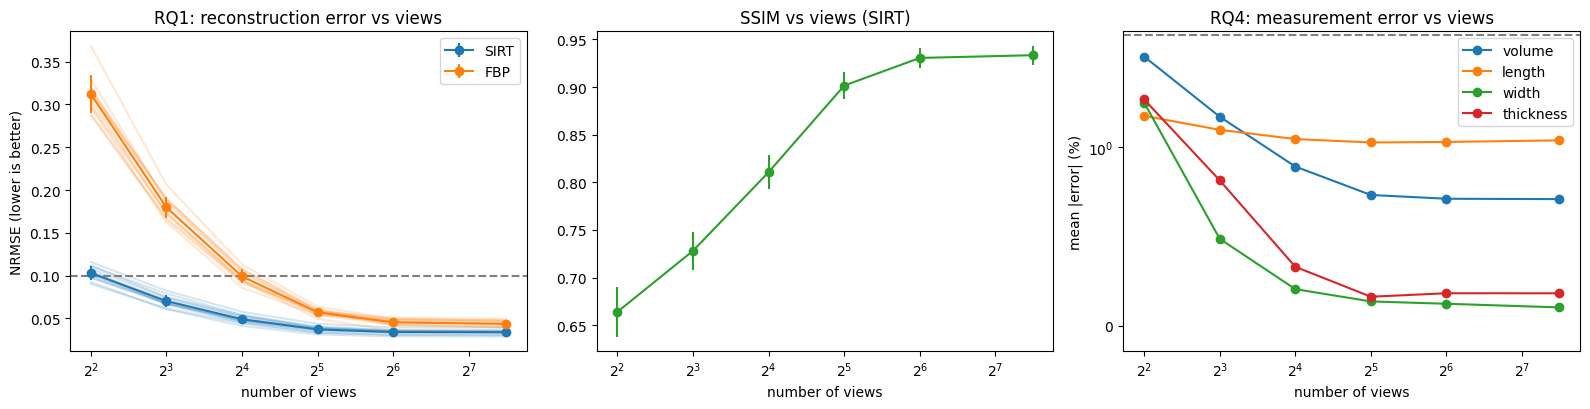

   kernel  K_90pct_gain  K_nrmse_tol  nrmse_dense
Group10_a            32            8       0.0359
Group11_e            32            8       0.0392
Group13_d            32            4       0.0337
Group15_c            32            8       0.0334
Group17_b            32            8       0.0305
Group19_a            32            4       0.0288
 Group1_a            32            8       0.0344
Group20_e            32            8       0.0352
 Group2_e            32            8       0.0360
 Group4_d            32            4       0.0340
 Group6_c            32            4       0.0345
 Group8_b            32            4       0.0310

mean NRMSE by views (SIRT):
      nrmse    ssim    dice
K                          
4    0.1030  0.6641  0.9692
8    0.0703  0.7282  0.9862
16   0.0492  0.8107  0.9914
32   0.0373  0.9015  0.9934
64   0.0341  0.9305  0.9938
180  0.0339  0.9334  0.9939


In [5]:
# ============ 4. RQ1 + RQ4: uniform views, 4..180 ============
for k in KERNELS:
    if done(k, "rq1"): continue
    R = get_ref(k); lib = R["lib"]; sino = fp(R["gpu"], lib); rows = []; t0 = time.time()
    for K in VIEW_COUNTS:
        idx = unif_idx(K)
        for method in ("sirt", "fbp"):
            rec = reconstruct(sino[:, idx], lib, idx, method)
            rows.append(dict(kernel=k, exp="rq1", strategy="uniform", K=K, seed=0, method=method, cond="ideal", noise=0.0, **evaluate(R, rec)))
    save_block(rows); print(f"{k}: done in {time.time() - t0:.0f}s"); del sino
    torch.cuda.empty_cache() if dev.type == "cuda" else None

r1 = res[(res.exp == "rq1")]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for method, c in (("sirt", "tab:blue"), ("fbp", "tab:orange")):
    g = r1[r1.method == method]
    for k, gk in g.groupby("kernel"): ax[0].plot(gk.K, gk.nrmse, color=c, alpha=.18)
    m = g.groupby("K").nrmse.agg(["mean", "std"]); ax[0].errorbar(m.index, m["mean"], m["std"], color=c, marker="o", label=method.upper())
ax[0].axhline(NRMSE_TOL, ls="--", c="gray"); ax[0].set_xscale("log", base=2); ax[0].set_xlabel("number of views"); ax[0].set_ylabel("NRMSE (lower is better)"); ax[0].legend(); ax[0].set_title("RQ1: reconstruction error vs views")
g = r1[r1.method == "sirt"]
m = g.groupby("K").ssim.agg(["mean", "std"]); ax[1].errorbar(m.index, m["mean"], m["std"], marker="o", c="tab:green"); ax[1].set_xscale("log", base=2); ax[1].set_title("SSIM vs views (SIRT)"); ax[1].set_xlabel("number of views")
for q, lab in (("vol_err", "volume"), ("L_err", "length"), ("W_err", "width"), ("T_err", "thickness")):
    m = g.assign(a=g[q].abs()).groupby("K").a.mean(); ax[2].plot(m.index, m.values, marker="o", label=lab)
ax[2].axhline(TOL_PCT, ls="--", c="gray"); ax[2].set_xscale("log", base=2); ax[2].set_yscale("symlog", linthresh=1); ax[2].set_xlabel("number of views"); ax[2].set_ylabel("mean |error| (%)"); ax[2].legend(); ax[2].set_title("RQ4: measurement error vs views")
plt.tight_layout(); plt.savefig(RES / "fig_rq1_rq4.png", dpi=110); plt.show()

# knee: smallest K that reaches 90% of the achievable improvement (4 views -> 180 views), per kernel
knees = []
for k, gk in g.groupby("kernel"):
    e = gk.set_index("K").nrmse; gain = (e[VIEW_COUNTS[0]] - e) / max(e[VIEW_COUNTS[0]] - e[VIEW_COUNTS[-1]], 1e-9)
    knees.append(dict(kernel=k, K_90pct_gain=int(gain[gain >= 0.9].index.min()), K_nrmse_tol=(int(e[e <= NRMSE_TOL].index.min()) if (e <= NRMSE_TOL).any() else None), nrmse_dense=round(e[VIEW_COUNTS[-1]], 4)))
knees = pd.DataFrame(knees); print(knees.to_string(index=False))
print(f"\nmean NRMSE by views (SIRT):\n{g.groupby('K')[['nrmse','ssim','dice']].mean().round(4).to_string()}")

## RQ2 - are some angles more informative?
At a fixed budget (8 and 16 views) three selection rules are compared on the same reconstruction algorithm: **uniform**, **random** (repeated draws), and **greedy oracle** (adds, one at a time, the candidate angle that most reduces the error on a few reference slices). The greedy rule is an upper-bound experiment, not a deployable policy.

             nrmse_mean  nrmse_sd    ssim  vol_abs_err  T_abs_err
K  strategy                                                      
8  greedy        0.0679    0.0053  0.7402       1.6408     0.5763
   random        0.0880    0.0094  0.7032       2.9072     1.8403
   uniform       0.0693    0.0059  0.7350       1.6388     0.9958
16 greedy        0.0483    0.0039  0.8162       0.9251     0.3244
   random        0.0675    0.0061  0.7654       1.6995     0.8441
   uniform       0.0482    0.0038  0.8168       0.8994     0.2156

per kernel (positive = better than uniform):
strategy      greedy  random  uniform  greedy_gain_vs_uniform_%  random_vs_uniform_%
kernel    K                                                                         
Group13_d 8    0.067   0.086    0.067                     1.100              -28.105
          16   0.047   0.065    0.047                    -0.586              -38.297
Group17_b 8    0.065   0.090    0.066                     2.799              -36.012
 

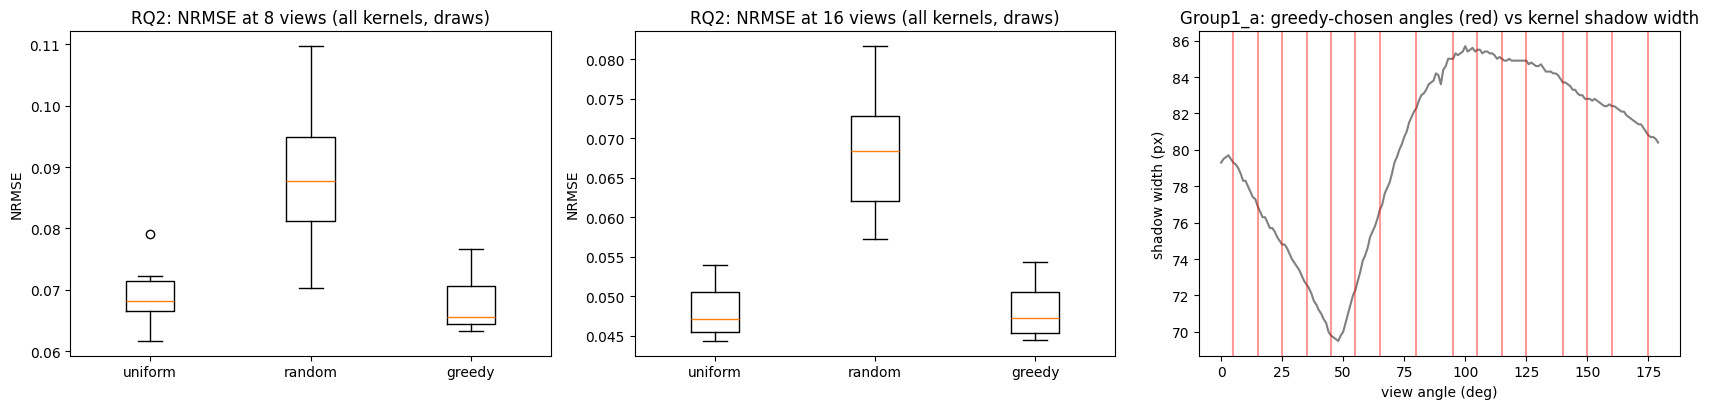

In [6]:
# ============ 5. RQ2: uniform vs random vs greedy at fixed budgets ============
K_RQ2 = spread(KERNELS, N_RQ2_KERNELS); rng = np.random.default_rng(SEED)
for k in K_RQ2:
    if done(k, "rq2"): continue
    R = get_ref(k); lib = R["lib"]; sino = fp(R["gpu"], lib); rows = []; t0 = time.time()
    chosen, traj = greedy_select(R, max(BUDGETS))
    shadow = (fp(torch.from_numpy(R["mask"][R["zs"][::8]].astype(np.float32)).to(dev), lib) > 0.5).sum(-1).float().mean(0).cpu().numpy()
    for K in BUDGETS:
        plans = [("uniform", 0, unif_idx(K)), ("greedy", 0, np.array(sorted(chosen[:K])))] + \
                [("random", s, np.sort(rng.choice(180, K, replace=False))) for s in range(N_RANDOM)]
        for strat, s, idx in plans:
            rec = sirt(sino[:, idx], lib, idx)
            rows.append(dict(kernel=k, exp="rq2", strategy=strat, K=K, seed=s, method="sirt", cond="ideal", noise=0.0,
                             angles=json.dumps([int(a) for a in idx]), greedy_traj=json.dumps(traj) if strat == "greedy" else "",
                             shadow=json.dumps([round(float(v), 1) for v in shadow]) if strat == "greedy" else "", **evaluate(R, rec)))
    save_block(rows); print(f"{k}: done in {time.time() - t0:.0f}s | greedy angles {sorted(chosen[:max(BUDGETS)])}"); del sino
    torch.cuda.empty_cache() if dev.type == "cuda" else None

r2 = res[res.exp == "rq2"]
summ = r2.groupby(["K", "strategy"]).agg(nrmse_mean=("nrmse", "mean"), nrmse_sd=("nrmse", "std"), ssim=("ssim", "mean"), vol_abs_err=("vol_err", lambda v: v.abs().mean()), T_abs_err=("T_err", lambda v: v.abs().mean())).round(4)
print(summ.to_string())
piv = r2.groupby(["kernel", "K", "strategy"]).nrmse.mean().unstack()
piv["greedy_gain_vs_uniform_%"] = 100 * (piv.uniform - piv.greedy) / piv.uniform; piv["random_vs_uniform_%"] = 100 * (piv.uniform - piv.random) / piv.uniform
print("\nper kernel (positive = better than uniform):"); print(piv.round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for j, K in enumerate(BUDGETS):
    d = r2[r2.K == K]; data = [d[d.strategy == s].nrmse.values for s in ("uniform", "random", "greedy")]
    ax[j].boxplot(data); ax[j].set_xticklabels(["uniform", "random", "greedy"]); ax[j].set_title(f"RQ2: NRMSE at {K} views (all kernels, draws)"); ax[j].set_ylabel("NRMSE")
gk = r2[(r2.strategy == "greedy") & (r2.K == max(BUDGETS))].iloc[0]
w = json.loads(gk.shadow); ax[2].plot(w, c="gray"); ax[2].set_xlabel("view angle (deg)"); ax[2].set_ylabel("shadow width (px)")
for a in json.loads(gk.angles): ax[2].axvline(a, c="r", alpha=.4)
ax[2].set_title(f"{gk.kernel}: greedy-chosen angles (red) vs kernel shadow width"); plt.tight_layout(); plt.savefig(RES / "fig_rq2.png", dpi=110); plt.show()

## RQ3, RQ4, RQ6 - shape dependence, task-level view counts, and a small predictor
Shape descriptors are computed from the reference masks (voxel units, converted to mm when the morphometrics sheet could be matched). Error-vs-shape results from a handful of kernels are indicative only.

calibration: ~40 um per experiment voxel (check against the Metadata sheet printed above)
   kernel      vol      L      W     T  elongation_L/W  cross_section_W/T
 Group1_a 898684.0 182.27 108.54 98.26            1.68               1.10
 Group2_e 743547.0 171.05 106.90 90.15            1.60               1.19
 Group4_d 474514.0 149.72  86.39 75.51            1.73               1.14
 Group6_c 498426.0 150.15  90.89 79.82            1.65               1.14
 Group8_b 462230.0 147.60  90.21 78.70            1.64               1.15
Group10_a 648133.0 162.88 104.89 85.05            1.55               1.23
Group11_e 625333.0 159.16  95.01 87.81            1.68               1.08
Group13_d 416349.0 144.01  81.54 74.19            1.77               1.10
Group15_c 453869.0 155.24  80.28 77.32            1.93               1.04
Group17_b 493426.0 147.24  91.94 82.74            1.60               1.11
Group19_a 391181.0 144.58  79.49 71.93            1.82               1.11
Group20_e 464996.0 157

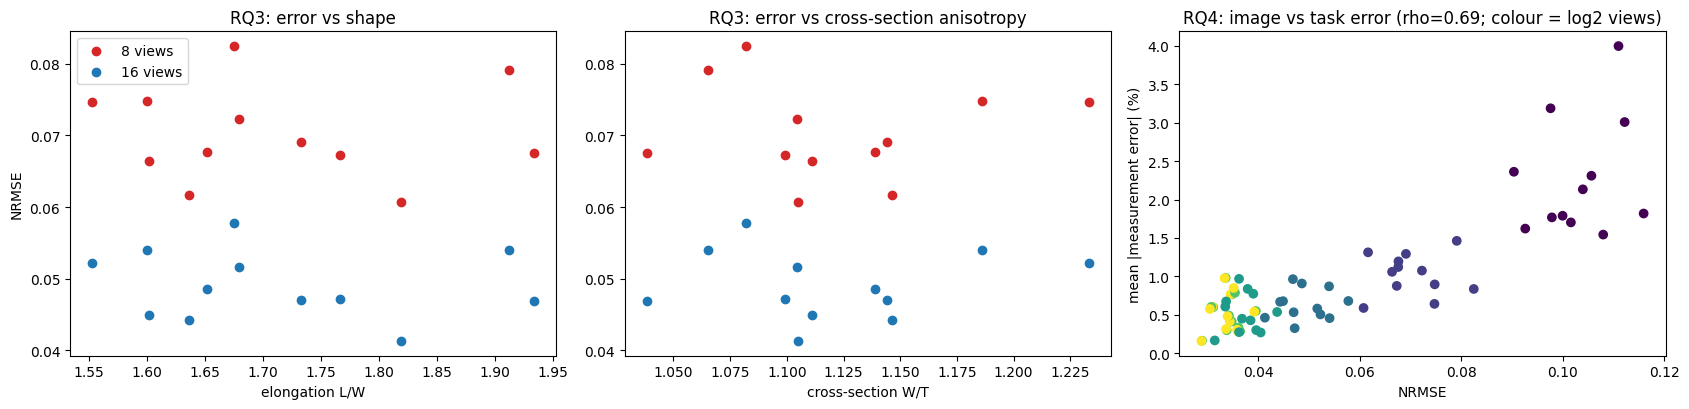

RQ6 leave-one-out MAE (log2 views): model 0.00 vs constant baseline 0.00 -> no evidence that shape helps (n=12)


In [7]:
# ============ 6. RQ3 / RQ4 / RQ6 analysis ============
desc = shape_table(); mm = calibrate(desc)
if not np.isnan(mm): print(f"calibration: ~{mm * 1000:.0f} um per experiment voxel (check against the Metadata sheet printed above)")
desc.to_csv(RES / "shape_descriptors.csv", index=False); print(desc.round(2).to_string(index=False))

s1 = res[(res.exp == "rq1") & (res.method == "sirt")]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
# RQ3: error vs shape at fixed uniform budgets
rq3 = []
for K, c in zip((8, 16), ("tab:red", "tab:blue")):
    d = s1[s1.K == K].merge(desc, on="kernel")
    for var, a_ in (("elongation_L/W", ax[0]), ("cross_section_W/T", ax[1])):
        a_.scatter(d[var], d.nrmse, c=c, label=f"{K} views")
        if len(d) >= 5: rho, p = spearmanr(d[var], d.nrmse); rq3.append(dict(K=K, descriptor=var, spearman=round(rho, 2), p=round(p, 3), n=len(d)))
ax[0].set_xlabel("elongation L/W"); ax[1].set_xlabel("cross-section W/T"); ax[0].set_ylabel("NRMSE"); ax[0].legend(); ax[0].set_title("RQ3: error vs shape"); ax[1].set_title("RQ3: error vs cross-section anisotropy")
print("\nRQ3 Spearman correlations (error vs shape):"); print(pd.DataFrame(rq3).to_string(index=False) if rq3 else "need >= 5 kernels")

# RQ4: smallest view count from which every measurement stays within TOL_PCT
need = []
for k, gk in s1.groupby("kernel"):
    gk = gk.sort_values("K"); row = dict(kernel=k)
    for q in ("vol_err", "L_err", "W_err", "T_err"):
        ok = gk[q].abs() <= TOL_PCT; Ks = gk.K.values
        row[q.replace("_err", "")] = next((int(Ks[i]) for i in range(len(Ks)) if ok.values[i:].all()), None)
    need.append(row)
need = pd.DataFrame(need); need["all_four"] = need[["vol", "L", "W", "T"]].max(axis=1)
print(f"\nRQ4: minimum uniform views to stay within +/-{TOL_PCT}% (None = not reached by 180):"); print(need.to_string(index=False))
c_ = s1.assign(m=s1[["vol_err", "L_err", "W_err", "T_err"]].abs().mean(axis=1))
rho = spearmanr(c_.nrmse, c_.m)[0]; print(f"image error vs measurement error (Spearman over all runs): {rho:.2f}")
ax[2].scatter(c_.nrmse, c_.m, c=np.log2(c_.K), cmap="viridis"); ax[2].set_xlabel("NRMSE"); ax[2].set_ylabel("mean |measurement error| (%)"); ax[2].set_title(f"RQ4: image vs task error (rho={rho:.2f}; colour = log2 views)")
plt.tight_layout(); plt.savefig(RES / "fig_rq3_rq4.png", dpi=110); plt.show()

# RQ6 (exploratory): predict required views from shape, leave-one-out; only meaningful with enough kernels
n_ = need.merge(desc, on="kernel").dropna(subset=["all_four"])
if len(n_) >= 8:
    X = np.c_[np.ones(len(n_)), n_["elongation_L/W"], n_["cross_section_W/T"]]; y = np.log2(n_.all_four.values.astype(float)); pred = []
    for i in range(len(n_)):
        tr = np.arange(len(n_)) != i; b = np.linalg.lstsq(X[tr], y[tr], rcond=None)[0]; pred.append(X[i] @ b)
    mae = np.mean(np.abs(np.array(pred) - y)); base = np.mean(np.abs(y - np.median(y)))
    print(f"RQ6 leave-one-out MAE (log2 views): model {mae:.2f} vs constant baseline {base:.2f} -> {'shape helps' if mae < base else 'no evidence that shape helps'} (n={len(n_)})")
else:
    print(f"RQ6 skipped: needs >= 8 kernels with a defined view count (have {len(n_)}).")

## RQ5 - robustness
At a fixed budget the three angle sets (uniform, random, greedy angles from RQ2) are reconstructed from sinograms with added Gaussian detector noise (sigma as a fraction of the sinogram maximum) and with a 1-pixel rotation-centre offset. The question is whether the ranking of strategies survives.

                 mean                     std                
strategy       greedy  random uniform  greedy  random uniform
cond_label                                                   
cor_shift_1px  0.0989  0.1016  0.0987  0.0084  0.0074  0.0082
noise 0.0      0.0495  0.0636  0.0493  0.0044  0.0047  0.0043
noise 0.01     0.0561  0.0683  0.0559  0.0049  0.0052  0.0049
noise 0.03     0.0924  0.0978  0.0923  0.0107  0.0099  0.0107
noise 0.05     0.1365  0.1372  0.1365  0.0161  0.0149  0.0160
noise 0.1      0.2326  0.2289  0.2329  0.0214  0.0207  0.0212

best strategy per condition: {'noise 0.0': 'uniform', 'noise 0.01': 'uniform', 'noise 0.03': 'uniform', 'noise 0.05': 'greedy', 'noise 0.1': 'random', 'cor_shift_1px': 'uniform'}


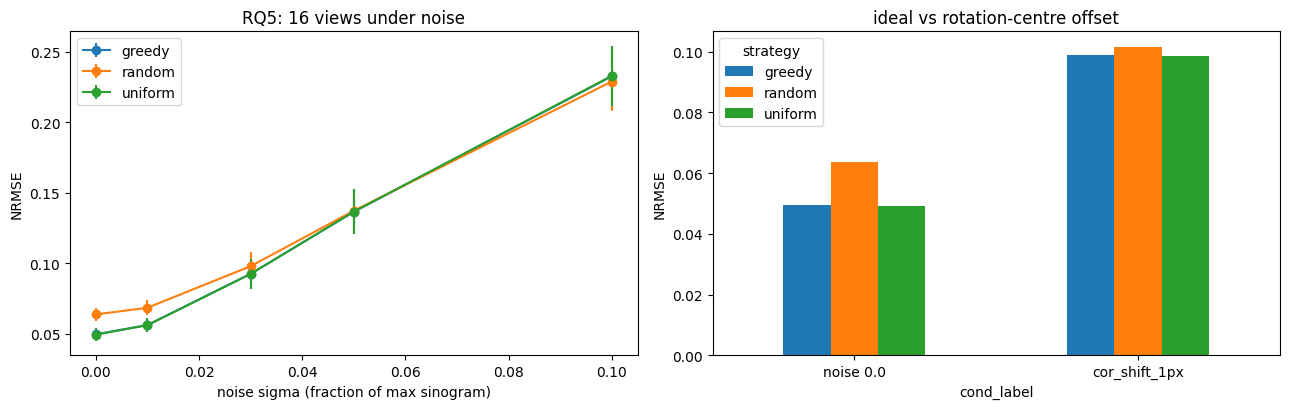

In [8]:
# ============ 7. RQ5: noise and rotation-centre offset ============
K5 = BUDGETS[-1]; r2g = res[(res.exp == "rq2") & (res.strategy == "greedy") & (res.K == K5)]
conds = [("noise", s) for s in NOISE_LEVELS] + [("cor_shift_1px", 0.0)]
for k in spread(KERNELS, N_RQ5_KERNELS):
    if done(k, "rq5"): continue
    R = get_ref(k); rows = []; t0 = time.time(); r5 = np.random.default_rng(SEED + 5)
    plans = [("uniform", 0, unif_idx(K5))] + [("random", s, np.sort(r5.choice(180, K5, replace=False))) for s in range(NOISE_SEEDS)]
    gr = r2g[r2g.kernel == k]
    if len(gr): plans.append(("greedy", 0, np.array(json.loads(gr.iloc[0].angles))))
    for cond, sg in conds:
        for strat, s, idx in plans:
            for ns in range(NOISE_SEEDS if sg > 0 else 1):
                rec, e = run_scenario(R, idx, noise=sg, cor_shift=1 if cond == "cor_shift_1px" else 0, seed=1000 * ns + s)
                rows.append(dict(kernel=k, exp="rq5", strategy=strat, K=K5, seed=s * 10 + ns, method="sirt", cond=cond, noise=sg, angles=json.dumps([int(a) for a in idx]), **e))
    save_block(rows); print(f"{k}: done in {time.time() - t0:.0f}s")
    torch.cuda.empty_cache() if dev.type == "cuda" else None

r5 = res[res.exp == "rq5"].copy(); r5["cond_label"] = np.where(r5.cond == "noise", "noise " + r5.noise.astype(str), r5.cond)
tab = r5.groupby(["cond_label", "strategy"]).nrmse.agg(["mean", "std"]).round(4).unstack()
print(tab.to_string())
order = [f"noise {s}" for s in NOISE_LEVELS] + ["cor_shift_1px"]
rank = r5.groupby(["cond_label", "strategy"]).nrmse.mean().unstack().loc[order]
print("\nbest strategy per condition:", rank.idxmin(axis=1).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for strat in rank.columns:
    d = r5[(r5.cond == "noise") & (r5.strategy == strat)].groupby("noise").nrmse.agg(["mean", "std"])
    ax[0].errorbar(d.index, d["mean"], d["std"].fillna(0), marker="o", label=strat)
ax[0].set_xlabel("noise sigma (fraction of max sinogram)"); ax[0].set_ylabel("NRMSE"); ax[0].set_title(f"RQ5: {K5} views under noise"); ax[0].legend()
rank.loc[["noise 0.0", "cor_shift_1px"]].plot.bar(ax=ax[1], rot=0); ax[1].set_title("ideal vs rotation-centre offset"); ax[1].set_ylabel("NRMSE")
plt.tight_layout(); plt.savefig(RES / "fig_rq5.png", dpi=110); plt.show()

In [9]:
# ============ 8. FINAL SUMMARY (paste this output back to me) ============
sirt1 = res[(res.exp == "rq1") & (res.method == "sirt")]
summary = {
    "n_kernels": len(KERNELS), "config": dict(POOL=POOL, SIRT_ITERS=SIRT_ITERS, VIEW_COUNTS=VIEW_COUNTS, TOL_PCT=TOL_PCT, voxel_um_estimate=(None if np.isnan(mm) else round(mm * 1000))),
    "rq1_mean_nrmse_by_views": sirt1.groupby("K").nrmse.mean().round(4).to_dict(),
    "rq1_fbp_mean_nrmse_by_views": res[(res.exp == "rq1") & (res.method == "fbp")].groupby("K").nrmse.mean().round(4).to_dict(),
    "rq1_knee_views_90pct": knees.K_90pct_gain.describe().round(1).to_dict(),
    "rq2_mean_nrmse": r2.groupby(["K", "strategy"]).nrmse.mean().round(4).unstack().to_dict(),
    "rq2_greedy_gain_vs_uniform_pct": piv["greedy_gain_vs_uniform_%"].groupby("K").mean().round(1).to_dict(),
    "rq3_spearman": rq3,
    "rq4_min_views_all_measurements": need.all_four.describe().round(1).to_dict() if len(need) else None,
    "rq4_mean_abs_err_pct_by_views": sirt1.assign(v=sirt1.vol_err.abs(), L=sirt1.L_err.abs(), W=sirt1.W_err.abs(), T=sirt1["T_err"].abs()).groupby("K")[["v", "L", "W", "T"]].mean().round(2).to_dict(),
    "rq5_best_strategy_per_condition": rank.idxmin(axis=1).to_dict(),
    "gpu_peak_GB": round(torch.cuda.max_memory_allocated() / 1e9, 2) if dev.type == "cuda" else None,
}
(RES / "summary.json").write_text(json.dumps(summary, indent=2, default=str)); print(json.dumps(summary, indent=2, default=str))
print("\nSaved to", RES, ":", sorted(p.name for p in RES.iterdir()))

{
  "n_kernels": 12,
  "config": {
    "POOL": 2,
    "SIRT_ITERS": 60,
    "VIEW_COUNTS": [
      4,
      8,
      16,
      32,
      64,
      180
    ],
    "TOL_PCT": 5.0,
    "voxel_um_estimate": 40
  },
  "rq1_mean_nrmse_by_views": {
    "4": 0.103,
    "8": 0.0703,
    "16": 0.0492,
    "32": 0.0373,
    "64": 0.0341,
    "180": 0.0339
  },
  "rq1_fbp_mean_nrmse_by_views": {
    "4": 0.3121,
    "8": 0.1796,
    "16": 0.0992,
    "32": 0.0572,
    "64": 0.0455,
    "180": 0.0437
  },
  "rq1_knee_views_90pct": {
    "count": 12.0,
    "mean": 32.0,
    "std": 0.0,
    "min": 32.0,
    "25%": 32.0,
    "50%": 32.0,
    "75%": 32.0,
    "max": 32.0
  },
  "rq2_mean_nrmse": {
    "greedy": {
      "8": 0.0679,
      "16": 0.0483
    },
    "random": {
      "8": 0.088,
      "16": 0.0675
    },
    "uniform": {
      "8": 0.0693,
      "16": 0.0482
    }
  },
  "rq2_greedy_gain_vs_uniform_pct": {
    "8": 1.9,
    "16": -0.2
  },
  "rq3_spearman": [
    {
      "K": 8,
      "desc

## Website-ready export
Writes everything a future web app needs into `XSeedFlow/web/` on Drive: the importable core (`xseedflow_core.py`), per-kernel 3-D meshes and reference volumes, precomputed reconstructions (views 4..180 and the greedy angle set), a `manifest.json` that includes the **UI parameter schema** (every control maps to one research question), and a short README. A backend only needs `get_ref` + `run_scenario`; the browser only needs the meshes and the manifest.

In [10]:
# ============ 9. WEBSITE-READY EXPORT ============
import datetime
WEBD = Path(ROOT) / "web"; (WEBD / "kernels").mkdir(parents=True, exist_ok=True)
desc = shape_table(); mm = calibrate(desc); vox_mm = None if np.isnan(mm) else round(mm, 5)
r1s = res[(res.exp == "rq1") & (res.method == "sirt")]; r2g = res[(res.exp == "rq2") & (res.strategy == "greedy")]
export_set = spread(KERNELS, EXPORT_N_KERNELS)
med_el = desc.set_index("kernel").loc[export_set, "elongation_L/W"].median()
DEMO_KERNEL = min(export_set, key=lambda k: abs(desc.set_index("kernel").loc[k, "elongation_L/W"] - med_el))
DEMO = {}; items = []
for k in KERNELS:
    R = get_ref(k); d = WEBD / "kernels" / k; d.mkdir(parents=True, exist_ok=True)
    refv = R["gpu"].cpu().numpy()
    np.save(d / "reference_u8.npy", (refv * 255).round().astype(np.uint8))
    vv, ff = mesh_from_volume(refv, R["thr"], step=1)
    (d / "mesh.json").write_text(json.dumps(dict(axes="vertices are x,y,z in voxel units", voxel_mm=vox_mm, vertices=np.round(vv[:, ::-1], 1).ravel().tolist(), faces=ff.ravel().tolist())))
    item = dict(name=k, folder=f"kernels/{k}", shape_zyx=list(R["shape"]), slice_size=R["S"], threshold=round(R["thr"], 4),
                reference_measurements_voxels={q: round(v, 2) for q, v in R["m"].items()},
                shape_descriptors={c: round(float(desc.set_index("kernel").loc[k, c]), 3) for c in ("elongation_L/W", "cross_section_W/T")},
                files=dict(reference="reference_u8.npy", mesh="mesh.json"), precomputed=[])
    if k in MATCHED: item["published_morphometrics"] = {c: (None if pd.isna(v) else float(v) if isinstance(v, (int, float, np.number)) else str(v)) for c, v in morph.loc[MATCHED[k]].items()}
    kn = r1s[r1s.kernel == k].sort_values("K")
    if len(kn):
        e = kn.set_index("K").nrmse; gain = (e[e.index.min()] - e) / max(e[e.index.min()] - e[e.index.max()], 1e-9)
        item["recommended_views_90pct_gain"] = int(gain[gain >= 0.9].index.min())
    gk = r2g[(r2g.kernel == k)]
    if len(gk): item["greedy_angles"] = {int(r.K): json.loads(r.angles) for r in gk.itertuples()}
    if k in export_set:
        plans = [("uniform", K, unif_idx(K)) for K in VIEW_COUNTS]
        if len(gk): plans += [("greedy", int(r.K), np.array(json.loads(r.angles))) for r in gk.itertuples()]
        for strat, K, idx in plans:
            rec, e = run_scenario(R, idx, full=False); fn = f"recon_{strat}_{K}.npy"
            np.save(d / fn, (rec.cpu().numpy() * 255).round().astype(np.uint8))
            item["precomputed"].append(dict(strategy=strat, views=int(K), angles=[int(a) for a in idx], file=fn, metrics={q: round(float(v), 4) for q, v in e.items()}))
            if k == DEMO_KERNEL and strat == "uniform": DEMO[K] = rec.cpu().numpy()
    items.append(item); print(f"exported {k}", "(with reconstructions)" if k in export_set else "")
    torch.cuda.empty_cache() if dev.type == "cuda" else None

ui_schema = [   # each control of the future website, the research question it serves, and the core-function argument it feeds
    dict(id="kernel", type="select", options=KERNELS, rq="all", label="Kernel"),
    dict(id="view_count", type="slider", min=2, max=180, default=16, rq="RQ1", label="Number of views", arg="angles (via angle_mode)"),
    dict(id="angle_mode", type="select", options=["uniform", "random", "greedy_oracle", "custom"], default="uniform", rq="RQ2", label="Angle selection", arg="angles"),
    dict(id="custom_angles", type="angle_picker", min=0, max=179, rq="RQ2", label="Pick angles on the half-circle", arg="angles"),
    dict(id="method", type="select", options=["sirt", "fbp"], default="sirt", rq="RQ1", label="Reconstruction algorithm", arg="method"),
    dict(id="iterations", type="slider", min=10, max=200, default=60, rq="RQ1", label="SIRT iterations", arg="iters"),
    dict(id="noise_sigma", type="slider", min=0.0, max=0.10, step=0.005, default=0.0, rq="RQ5", label="Detector noise (fraction of max signal)", arg="noise"),
    dict(id="cor_shift_px", type="slider", min=-3, max=3, step=1, default=0, rq="RQ5", label="Rotation-centre offset (pixels)", arg="cor_shift"),
    dict(id="threshold_scale", type="slider", min=0.7, max=1.3, step=0.05, default=1.0, rq="RQ4", label="Segmentation threshold (x Otsu)", arg="thr_scale"),
    dict(id="tolerance_pct", type="slider", min=1, max=10, default=TOL_PCT, rq="RQ4", label="Allowed measurement error (%)", arg="(frontend: pass/fail badge)"),
    dict(id="view_mode", type="toggle", options=["3d_surface_deviation", "axial_slice", "sinogram", "error_map"], rq="RQ1/RQ2", label="Display"),
    dict(id="slice_index", type="slider", min=0, max="shape_zyx[0]-1", rq="RQ1", label="Axial slice")]
outputs = ["nrmse", "ssim", "dice", "vol_err", "L_err", "W_err", "T_err (percent error vs reference)", "reconstructed volume (uint8)", "surface mesh + vertex deviation"]
manifest = dict(created=datetime.datetime.now().isoformat(timespec="seconds"), dataset="Shi et al., Sci Data 13, 804 (2026); Figshare 10.6084/m9.figshare.30145858",
                geometry="parallel beam; views = rotations about the kernel long axis; angle library 0..179 deg, 1 deg steps; one 2-D problem per axial slice",
                experiment_voxel_mm_estimate=vox_mm, pool=POOL, sirt_iterations=SIRT_ITERS, core_module="xseedflow_core.py",
                caveats=["projections are simulated from reconstructed slices (inverse crime)", "greedy_oracle uses the reference volume", "voxel size is self-calibrated from published major-axis length"],
                ui_schema=ui_schema, outputs=outputs, kernels=items)
(WEBD / "manifest.json").write_text(json.dumps(manifest, indent=1, default=str))
(WEBD / "README.md").write_text("""# XSeedFlow web assets

* `xseedflow_core.py` - the exact code used in the notebook (PyTorch only). Backend usage:

```python
import xseedflow_core as core, numpy as np
core.paths["Group1_a"] = "/path/to/Group1_a.npz"      # processed file from Step 0
R = core.get_ref("Group1_a")
angles = core.unif_idx(16)                             # or core.greedy_select(R, 16)[0], or user-picked angles 0..179
rec, metrics = core.run_scenario(R, angles, method="sirt", iters=60, noise=0.02, cor_shift=1, thr_scale=1.0, full=True)
verts, faces = core.mesh_from_volume(rec.cpu().numpy(), R["thr"] )
dev_ = core.surface_deviation(R["mask"], verts)        # colour the 3-D surface by deviation from the reference
```
* `manifest.json` - kernels, descriptors, precomputed scenarios and `ui_schema` (the controls, each tagged with the research question it serves).
* `kernels/<name>/mesh.json` - reference surface for three.js / plotly; `reference_u8.npy` and `recon_*_*.npy` - uint8 volumes (z,y,x), value/255.
""")
print(f"\nweb assets in {WEBD}: {sum(p.stat().st_size for p in WEBD.rglob('*') if p.is_file()) / 1e6:.1f} MB | demo kernel for the report: {DEMO_KERNEL}")

exported Group1_a (with reconstructions)
exported Group2_e 
exported Group4_d 
exported Group6_c 
exported Group8_b (with reconstructions)
exported Group10_a 
exported Group11_e 
exported Group13_d (with reconstructions)
exported Group15_c 
exported Group17_b 
exported Group19_a 
exported Group20_e (with reconstructions)

web assets in /content/drive/MyDrive/XSeedFlow/web: 130.9 MB | demo kernel for the report: Group1_a


## Interactive results report (self-contained HTML, saved to Drive)
Builds `XSeedFlow/report/xseedflow_report.html`: a single offline file (Plotly inlined) with KPI cards, the diminishing-returns curve, a polar map of the angles the greedy search prefers, strategy slope-graphs, a measurement-error heatmap, shape and robustness views, and two interactive explorers - a 3-D kernel with a *surface-deviation* colour map and a slice explorer, both with a views slider.

In [11]:
# ============ 10. HTML REPORT ============
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from plotly.offline import get_plotlyjs

INK, MUTE = "#e8ecf8", "#8b95b8"; CY, VI, PK, AM, GR = "#6ee7f9", "#a78bfa", "#f472b6", "#fbbf24", "#34d399"
def style(fig, h=360):
    fig.update_layout(template="plotly_dark", paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)", height=h,
                      font=dict(family="Inter,Segoe UI,system-ui,sans-serif", color=INK, size=13), margin=dict(l=55, r=25, t=50, b=50),
                      legend=dict(bgcolor="rgba(0,0,0,0)"), hoverlabel=dict(bgcolor="#1b2447", font_size=12))
    fig.update_xaxes(gridcolor="rgba(255,255,255,.07)", zeroline=False); fig.update_yaxes(gridcolor="rgba(255,255,255,.07)", zeroline=False)
    return fig
H = lambda fig, div_id=None: fig.to_html(full_html=False, include_plotlyjs=False, auto_play=False, div_id=div_id, config=dict(displaylogo=False, responsive=True))
def slider(names, prefix):
    return [dict(active=0, currentvalue=dict(prefix=prefix, font=dict(color=INK)), pad=dict(t=35), bgcolor="#1b2447", font=dict(color=MUTE),
                 steps=[dict(method="animate", label=str(n), args=[[str(n)], dict(mode="immediate", frame=dict(duration=0, redraw=True), transition=dict(duration=0))]) for n in names])]

s1 = res[(res.exp == "rq1") & (res.method == "sirt")]; f1 = res[(res.exp == "rq1") & (res.method == "fbp")]
r2 = res[res.exp == "rq2"]; r5 = res[res.exp == "rq5"].copy(); Ks = sorted(s1.K.unique()); sections = []
desc = shape_table(); KB = max(BUDGETS)
def pct_saved(K): return 100 * (1 - K / 180)

# ---------- F1: diminishing returns ----------
m = s1.groupby("K").nrmse.agg(["mean", "std"]).loc[Ks]; sd = m["std"].fillna(0); mf = f1.groupby("K").nrmse.mean().loc[Ks]
fig = make_subplots(rows=1, cols=2, column_widths=[.64, .36], subplot_titles=("Reconstruction error vs number of views", "Improvement bought by each extra view"))
for k, gk in s1.groupby("kernel"): fig.add_trace(go.Scatter(x=gk.K.astype(str), y=gk.nrmse, mode="lines", line=dict(color="rgba(110,231,249,.2)", width=1), hoverinfo="skip", showlegend=False), 1, 1)
Kc = [str(k) for k in Ks]
fig.add_trace(go.Scatter(x=Kc + Kc[::-1], y=list(m["mean"] + sd) + list((m["mean"] - sd)[::-1]), fill="toself", fillcolor="rgba(110,231,249,.14)", line=dict(width=0), hoverinfo="skip", showlegend=False), 1, 1)
fig.add_trace(go.Scatter(x=Kc, y=m["mean"], name="SIRT (mean +/- sd)", mode="lines+markers", line=dict(color=CY, width=3), marker=dict(size=9), customdata=[pct_saved(K) for K in Ks], hovertemplate="%{x} views (%{customdata:.0f}% fewer than 180)<br>NRMSE %{y:.4f}<extra>SIRT</extra>"), 1, 1)
fig.add_trace(go.Scatter(x=Kc, y=mf, name="FBP", mode="lines+markers", line=dict(color=AM, width=2, dash="dot"), marker=dict(size=7)), 1, 1)
fig.add_hline(y=NRMSE_TOL, line=dict(color=MUTE, dash="dash"), annotation_text=f"target NRMSE {NRMSE_TOL}", annotation_font_color=MUTE, row=1, col=1)
med_knee = float(np.median(knees.K_90pct_gain)); xk = int(np.argmin([abs(k - med_knee) for k in Ks]))      # category position (0-based)
fig.add_shape(type="line", x0=xk, x1=xk, y0=0, y1=1, xref="x", yref="y domain", line=dict(color=PK, dash="dash"))
fig.add_annotation(x=xk, y=1, xref="x", yref="y domain", text=f"90% of the gain by ~{med_knee:.0f} views", showarrow=False, xanchor="left", yanchor="top", font=dict(color=PK))
gpv = -np.diff(m["mean"].values) / np.diff(Ks)
fig.add_trace(go.Bar(x=[f"{a}->{b}" for a, b in zip(Ks[:-1], Ks[1:])], y=np.maximum(gpv, 1e-7), marker=dict(color=gpv, colorscale=[[0, "#312e81"], [1, PK]]), showlegend=False, hovertemplate="%{x} views<br>%{y:.2e} NRMSE per extra view<extra></extra>"), 1, 2)
fig.update_xaxes(type="category", title_text="number of views", row=1, col=1); fig.update_yaxes(title_text="NRMSE (lower is better)", row=1, col=1)
fig.update_yaxes(type="log", title_text="NRMSE gained per added view", row=1, col=2); fig.update_layout(legend=dict(orientation="h", y=-0.22, x=0))
ratio_lo, ratio_hi = float(mf.iloc[0] / m["mean"].iloc[0]), float(mf.iloc[-1] / m["mean"].iloc[-1])
t1 = (f"The median kernel reaches 90% of the achievable gain (4 views to 180 views) with about {med_knee:.0f} views, i.e. {pct_saved(med_knee):.0f}% fewer projections than the 180-view baseline; beyond that each extra view buys little. "
      f"FBP error is {ratio_lo:.1f}x the SIRT error at {Ks[0]} views and {ratio_hi:.2f}x at {Ks[-1]} views, so the reconstruction algorithm matters most in the sparse regime. (Fewer projections is not the same as proportionally shorter scan time.)")
sections.append(("rq1", "RQ1", "How many views are actually necessary?", "Where do additional projections stop paying off?", [H(style(fig, 376))], t1))

# ---------- F2 + F3: angles and strategies (RQ2) ----------
figs2 = []
g2 = r2[(r2.strategy == "greedy") & (r2.K == KB)]
if len(g2):
    angs = np.concatenate([json.loads(a) for a in g2.angles]); cnt, edges = np.histogram(angs, bins=np.arange(0, 181, 10))
    sh = np.mean([np.array(json.loads(s_)) for s_ in g2.shadow if s_ and len(json.loads(s_)) == 180], axis=0) if any(isinstance(s_, str) and s_ for s_ in g2.shadow) else None
    fp_ = go.Figure(go.Barpolar(theta=edges[:-1] + 5, r=cnt, width=[9] * len(cnt), marker=dict(color=cnt, colorscale=[[0, "#312e81"], [1, CY]], line=dict(color="#0b1020", width=1)), name="times chosen",
                                hovertemplate="%{theta:.0f} deg<br>chosen %{r}x<extra></extra>"))
    if sh is not None: fp_.add_trace(go.Scatterpolar(theta=np.arange(180), r=(sh - sh.min()) / max(np.ptp(sh), 1e-6) * max(cnt.max(), 1), mode="lines", line=dict(color=PK, width=3), name="kernel shadow width (scaled)"))
    fp_.update_layout(polar=dict(sector=[0, 180], bgcolor="rgba(0,0,0,0)", radialaxis=dict(gridcolor="rgba(255,255,255,.1)", tickfont=dict(color=MUTE)), angularaxis=dict(gridcolor="rgba(255,255,255,.1)", direction="counterclockwise")), title=f"Angles picked by the greedy search ({KB} views, all kernels)")
    figs2.append(H(style(fp_, 352)))
    sl = make_subplots(rows=1, cols=len(BUDGETS), subplot_titles=[f"{K} views" for K in BUDGETS], shared_yaxes=False)
    for j, K in enumerate(BUDGETS, 1):
        d = r2[r2.K == K].groupby(["kernel", "strategy"]).nrmse.mean().unstack()
        for k, row in d.iterrows():
            better = row.greedy < row.uniform
            sl.add_trace(go.Scatter(x=["uniform", "random", "greedy"], y=[row.uniform, row.random, row.greedy], mode="lines+markers", line=dict(color=GR if better else PK, width=2), marker=dict(size=8),
                                    name=k, showlegend=False, hovertemplate=f"{k}<br>%{{x}}: %{{y:.4f}}<extra></extra>"), 1, j)
    sl.update_yaxes(title_text="NRMSE", row=1, col=1); sl.update_layout(title="Same budget, different angles (green = greedy beats uniform for that kernel)")
    figs2.append(H(style(sl, 352)))
pv = r2.groupby(["kernel", "K", "strategy"]).nrmse.mean().unstack()
gain = float((100 * (pv.uniform - pv.greedy) / pv.uniform).mean()); rgain = float((100 * (pv.uniform - pv.random) / pv.uniform).mean())
wins = int(((pv.greedy < pv.uniform)).sum()); tot = int(len(pv))
t2 = (f"Averaged over kernels and budgets, the greedy oracle changes NRMSE by {gain:+.1f}% relative to uniform spacing (positive = better) and wins {wins}/{tot} kernel-budget cases; random selection changes it by {rgain:+.1f}%. "
      + ("Strategic angles help here, though the oracle uses the reference volume." if gain > 2 else "Uniform spacing is already hard to beat on these near-cylindrical kernels, which is itself a finding.")
      + " The polar plot shows which view directions the search keeps asking for relative to the kernel's shadow width.")
sections.append(("rq2", "RQ2", "Are some viewing angles more informative?", "At a fixed view budget, does where you look matter more than how often?", figs2, t2))

# ---------- F4/F5: measurements (RQ4) ----------
meas = s1.assign(Volume=s1.vol_err.abs(), Length=s1.L_err.abs(), Width=s1.W_err.abs(), Thickness=s1["T_err"].abs()).groupby("K")[["Volume", "Length", "Width", "Thickness"]].mean().loc[Ks]
hm = go.Figure(go.Heatmap(z=meas.T.values, x=[str(k) for k in Ks], y=list(meas.columns), text=np.round(meas.T.values, 1), texttemplate="%{text}%", zmin=0, zmax=float(max(1, np.ceil(meas.values.max()))),
                          colorscale=[[0, "#064e3b"], [.25, GR], [.5, AM], [1, "#ef4444"]], colorbar=dict(title="mean |error| %"), hovertemplate="%{y} at %{x} views: %{z:.2f}%<extra></extra>"))
hm.update_layout(title=f"Biological measurements vs number of views (tolerance {TOL_PCT}%)", xaxis_title="views", yaxis=dict(autorange="reversed"))
c_ = s1.assign(me=s1[["vol_err", "L_err", "W_err", "T_err"]].abs().mean(axis=1))
sc = go.Figure(go.Scatter(x=c_.nrmse, y=c_.me, mode="markers", marker=dict(size=11, color=np.log2(c_.K), colorscale=[[0, PK], [.5, VI], [1, CY]], colorbar=dict(title="log2 views"), line=dict(color="#0b1020", width=1)),
                          text=[f"{k} | {K} views" for k, K in zip(c_.kernel, c_.K)], hovertemplate="%{text}<br>NRMSE %{x:.4f}<br>task error %{y:.2f}%<extra></extra>"))
rho = spearmanr(c_.nrmse, c_.me)[0]; sc.update_layout(title=f"Image error vs task error (Spearman rho = {rho:.2f})", xaxis_title="NRMSE (image)", yaxis_title="mean |measurement error| (%)", xaxis_type="log")
okK = [int(r["all_four"]) for _, r in need.iterrows() if pd.notna(r["all_four"])]
hard = meas.loc[Ks[:3]].mean().idxmax()
t4 = (f"All four measurements stay within {TOL_PCT}% from a median of {np.median(okK):.0f} views on {len(okK)}/{len(need)} kernels. Image error and task error are correlated (rho = {rho:.2f}) but not interchangeable, so a view count should be certified per measurement and not by a single image score. "
      f"At low view counts the largest error is on {hard.lower()}.") if okK else "The tolerance was not reached within 180 views for any kernel; relax TOL_PCT or inspect the segmentation threshold."
sections.append(("rq4", "RQ4", "Do reconstructions keep the measurements biologists need?", "Is a rough-looking reconstruction still good enough for length, width, thickness and volume?", [H(style(hm, 320)), H(style(sc, 320))], t4))

# ---------- F6: shape (RQ3) ----------
d6 = s1[s1.K.isin(BUDGETS)].merge(desc, on="kernel"); fg = go.Figure()
for K, col in zip(BUDGETS, (PK, CY, VI, AM)):
    d = d6[d6.K == K]
    fg.add_trace(go.Scatter(x=d["elongation_L/W"], y=d.nrmse, mode="markers+text", text=d.kernel.str.replace("Group", "G"), textposition="top center", textfont=dict(size=9, color=MUTE), name=f"{K} views",
                            marker=dict(size=np.sqrt(d.vol) / np.sqrt(d.vol).max() * 34 + 6, color=col, opacity=.75, line=dict(color="#0b1020", width=1)), hovertemplate="%{text}<br>L/W %{x:.2f}<br>NRMSE %{y:.4f}<extra></extra>"))
    if len(d) >= 3: p = np.polyfit(d["elongation_L/W"], d.nrmse, 1); xs = np.linspace(d["elongation_L/W"].min(), d["elongation_L/W"].max(), 20); fg.add_trace(go.Scatter(x=xs, y=np.polyval(p, xs), mode="lines", line=dict(color=col, dash="dot"), showlegend=False, hoverinfo="skip"))
fg.update_layout(title="Reconstruction error vs kernel elongation (bubble = volume)", xaxis_title="elongation L/W", yaxis_title="NRMSE")
rq3t = pd.DataFrame(rq3) if len(rq3) else pd.DataFrame()
t3 = ("Spearman correlations of error with shape: " + "; ".join(f"{r.descriptor} @ {r.K} views rho={r.spearman:+.2f} (p={r.p:.2f})" for r in rq3t.itertuples()) + f". With only {d6.kernel.nunique()} kernels these are hints, not conclusions - the point of the pipeline is that adding kernels is a config change.") if len(rq3t) else "Too few kernels for correlation statistics; the scatter shows the raw relationship."
sections.append(("rq3", "RQ3", "Does the best acquisition depend on seed shape?", "Do long or flat kernels need more views than round ones?", [H(style(fg, 352))], t3))

# ---------- F7: robustness (RQ5) ----------
figs5 = []
if len(r5):
    r5["lab"] = np.where(r5.cond == "noise", "noise " + r5.noise.astype(str), r5.cond); order = [f"noise {s}" for s in NOISE_LEVELS] + ["cor_shift_1px"]
    rk = r5.groupby(["lab", "strategy"]).nrmse.mean().unstack().loc[order]; base = rk.iloc[0]
    nz = go.Figure()
    for strat, col in zip(rk.columns, (CY, PK, AM, GR)):
        d = r5[(r5.cond == "noise") & (r5.strategy == strat)].groupby("noise").nrmse.agg(["mean", "std"])
        nz.add_trace(go.Scatter(x=d.index, y=d["mean"], error_y=dict(type="data", array=d["std"].fillna(0).values, color=col, thickness=1.2), mode="lines+markers", name=strat, line=dict(color=col, width=3), marker=dict(size=9)))
    nz.update_layout(title=f"{KB} views under detector noise", xaxis_title="noise sigma (fraction of max sinogram)", yaxis_title="NRMSE"); figs5.append(H(style(nz, 336)))
    deg = (rk / base - 1) * 100
    hd = go.Figure(go.Heatmap(z=deg.values, x=list(deg.columns), y=[o.replace("cor_shift_1px", "centre offset 1px") for o in deg.index], colorscale=[[0, "#064e3b"], [.35, AM], [1, "#ef4444"]], text=np.round(deg.values, 0), texttemplate="%{text}%",
                              colorbar=dict(title="% worse than ideal"), hovertemplate="%{x} | %{y}: %{z:.1f}% worse<extra></extra>"))
    hd.update_layout(title="Degradation relative to the ideal simulation", yaxis=dict(autorange="reversed")); figs5.append(H(style(hd, 336)))
    best = rk.idxmin(axis=1); t5 = f"Best strategy per condition: " + "; ".join(f"{i.replace('cor_shift_1px', 'centre offset')} -> {b}" for i, b in best.items()) + ". If the ranking changes with noise, an advantage seen in the ideal simulation is not robust. A 1-pixel rotation-centre error shows how sensitive the whole chain is to geometry mismatch."
    sections.append(("rq5", "RQ5", "Do conclusions survive a less ideal simulation?", "What happens to the strategies when projections are noisy or the geometry is slightly wrong?", figs5, t5))

# ---------- F8: 3-D surface deviation explorer + F9: slice explorer ----------
R = get_ref(DEMO_KERNEL); refv = R["gpu"].cpu().numpy(); Kd = sorted(DEMO)
rv, rf = mesh_from_volume(refv, R["thr"], step=2)
frames, data0 = [], None
for K in Kd:
    v_, f_ = mesh_from_volume(DEMO[K], R["thr"], step=2); dv = surface_deviation(R["mask"], v_)
    tr = go.Mesh3d(x=v_[:, 2], y=v_[:, 1], z=v_[:, 0], i=f_[:, 0], j=f_[:, 1], k=f_[:, 2], intensity=dv, intensitymode="vertex", colorscale="RdBu", reversescale=True, cmin=-3, cmax=3, flatshading=False,
                   colorbar=dict(title="deviation<br>(voxels)", thickness=14, len=.75), lighting=dict(ambient=.55, diffuse=.8, specular=.3), name=f"{K} views")
    frames.append(go.Frame(data=[tr], traces=[1], name=str(K)))
    if data0 is None: data0 = tr
ghost = go.Mesh3d(x=rv[:, 2], y=rv[:, 1], z=rv[:, 0], i=rf[:, 0], j=rf[:, 1], k=rf[:, 2], color="#94a3b8", opacity=.12, name="reference", hoverinfo="skip")
f8 = go.Figure(data=[ghost, data0], frames=frames)
f8.update_layout(title=dict(text=f"3D kernel {DEMO_KERNEL} - drag to rotate, scroll to zoom (red = outside the reference, blue = inside)", font=dict(size=14)), scene=dict(aspectmode="data", camera=dict(eye=dict(x=1.7, y=1.1, z=.6)), xaxis_visible=False, yaxis_visible=False, zaxis_visible=False, bgcolor="rgba(0,0,0,0)"))
zc = R["zs"][len(R["zs"]) // 2]; ref_s = refv[zc]
f9 = make_subplots(rows=1, cols=3, subplot_titles=("reference slice", "reconstruction", "error (rec - ref)"), horizontal_spacing=.04)
f9.add_trace(go.Heatmap(z=ref_s, colorscale="Gray", zmin=0, zmax=1, showscale=False), 1, 1)
mkh = lambda K: (go.Heatmap(z=DEMO[K][zc], colorscale="Gray", zmin=0, zmax=1, showscale=False), go.Heatmap(z=DEMO[K][zc] - ref_s, colorscale="RdBu", reversescale=True, zmin=-.5, zmax=.5, colorbar=dict(title="error", x=1.02)))
a_, b_ = mkh(Kd[0]); f9.add_trace(a_, 1, 2); f9.add_trace(b_, 1, 3)
f9.frames = [go.Frame(data=list(mkh(K)), traces=[1, 2], name=str(K)) for K in Kd]
for c in (1, 2, 3): f9.update_xaxes(visible=False, row=1, col=c, scaleanchor=f"y{'' if c == 1 else c}"); f9.update_yaxes(visible=False, autorange="reversed", row=1, col=c)
f9.update_layout(margin=dict(l=20, r=40, t=40, b=20))
# ---------- one thin control (slider + clickable numbers) attached UNDER each interactive plot ----------
def make_ctrl(plot_id):
    ticks = "".join(f'<button class="tick{" on" if i == 0 else ""}" data-i="{i}">{K}</button>' for i, K in enumerate(Kd))
    return (f'<div class="ctrl" data-plot="{plot_id}"><div class="chead"><span>Drag the slider (or tap a number) to change the number of X-ray views</span><b class="cur"></b></div>'
            f'<input type="range" class="xsr" min="0" max="{len(Kd) - 1}" step="1" value="0" aria-label="number of views"><div class="ticks">{ticks}</div></div>')
EXPLORE_JS = """<script>(function(){var V=__VIEWS__;
function init(root,plotId){var ticks=root.querySelectorAll(".tick"),rng=root.querySelector("input"),cur=root.querySelector(".cur");
function setIdx(i,go){rng.value=i;ticks.forEach(function(t,j){t.classList.toggle("on",j===i)});
cur.textContent=V[i]+" views"+(V[i]<180?" ("+Math.round(100*(1-V[i]/180))+"% fewer than 180)":" (full set)");
if(!go||!window.Plotly)return;var g=document.getElementById(plotId);if(g)Plotly.animate(g,[String(V[i])],{mode:"immediate",frame:{duration:0,redraw:true},transition:{duration:0}})}
rng.addEventListener("input",function(){setIdx(+rng.value,true)});ticks.forEach(function(t){t.addEventListener("click",function(){setIdx(+t.dataset.i,true)})});setIdx(0,false)}
document.querySelectorAll(".ctrl").forEach(function(c){init(c,c.dataset.plot)})})();</script>""".replace("__VIEWS__", json.dumps(Kd))
t8 = "Colour on the 3-D surface shows how far each point of the reconstruction is from the reference surface (red = outside it, blue = inside it); the slice panel shows the matching error map. Each plot has its own slider under it, so you can compare two different numbers of views. The website will expose the same controls on any kernel."
sections.append(("explore", "Try it", "See what a view budget does to a real kernel", "Interactive: choose the number of X-ray views and watch the 3-D kernel and its error change.",
                 [H(style(f8, 430), "xs3d") + make_ctrl("xs3d"), H(style(f9, 360), "xsslice") + make_ctrl("xsslice")], t8))
sections.sort(key=lambda t: t[0] != "explore")      # interactive section first

# ---------- dataset numbers (shown once, small, under the subtitle) ----------
dense = float(s1[s1.K == max(Ks)].nrmse.mean())
kpis = [(f"{len(KERNELS)}", "kernels analysed"), (f"{med_knee:.0f}", "views for 90% of the gain (median)"), (f"{pct_saved(med_knee):.0f}%", "fewer projections than 180"),
        (f"{np.median(okK):.0f}" if okK else "n/a", f"views to keep all measurements within {TOL_PCT}%"), (f"{gain:+.1f}%", "greedy angles vs uniform (NRMSE)"), (f"{dense:.3f}", "dense-view NRMSE floor")]
nav = "".join(f'<a href="#{sid}">{tag}</a>' for sid, tag, *_ in sections)
body = "".join(f'<section id="{sid}"><div class="tag">{tag}</div><h2>{title}</h2><p class="q">{q}</p><div class="grid' + (' one' if sid == 'explore' else '') + '">' + "".join(f'<div class="card">{f}</div>' for f in figs) + f'</div><div class="take"><b>What the data say.</b> {take}</div></section>' for sid, tag, title, q, figs, take in sections)
stats = "".join(f'<span class="st"><b>{v}</b> {l}</span>' for v, l in kpis)
CSS = """
:root{--bg:#0b1020;--panel:#121a33;--ink:#e8ecf8;--mute:#8b95b8;--cy:#6ee7f9;--vi:#a78bfa;--pk:#f472b6}
*{box-sizing:border-box}html{scroll-behavior:smooth}
body{margin:0;background:radial-gradient(1200px 600px at 15% -10%,#1b2a5e 0%,transparent 60%),radial-gradient(900px 500px at 95% 5%,#3b1d5e 0%,transparent 55%),var(--bg);color:var(--ink);font-family:Inter,'Segoe UI',system-ui,sans-serif;line-height:1.55}
header{padding:34px 6vw 10px}.eyebrow{letter-spacing:.2em;text-transform:uppercase;font-size:12px;color:var(--cy)}
h1{font-size:clamp(28px,4.2vw,48px);margin:8px 0;background:linear-gradient(90deg,var(--cy),var(--vi),var(--pk));-webkit-background-clip:text;background-clip:text;color:transparent;line-height:1.1}
.sub{max-width:820px;color:var(--mute);font-size:16px;margin:6px 0 16px}
nav{position:sticky;top:0;z-index:20;display:flex;gap:8px;flex-wrap:wrap;padding:12px 6vw;backdrop-filter:blur(14px);background:rgba(11,16,32,.7);border-bottom:1px solid rgba(255,255,255,.06)}
nav a{color:var(--ink);text-decoration:none;font-size:13px;padding:6px 14px;border-radius:99px;border:1px solid rgba(255,255,255,.12)}nav a:hover{background:linear-gradient(90deg,var(--vi),var(--pk));border-color:transparent}
.stats{display:flex;flex-wrap:wrap;gap:6px 20px;margin:0 0 16px;font-size:13px;color:var(--mute)}.st b{font-size:17px;font-weight:700;background:linear-gradient(90deg,var(--cy),var(--vi));-webkit-background-clip:text;background-clip:text;color:transparent;margin-right:3px}
section{padding:30px 6vw 6px;scroll-margin-top:60px}.tag{display:inline-block;font-size:12px;font-weight:700;letter-spacing:.14em;color:#0b1020;background:linear-gradient(90deg,var(--cy),var(--vi));padding:3px 12px;border-radius:99px}
h2{margin:12px 0 4px;font-size:clamp(22px,3vw,32px)}.q{color:var(--mute);margin:0 0 18px;font-size:16px}
.grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(min(100%,520px),1fr));gap:16px}
.card,.grid>*{min-width:0}.card .plotly-graph-div{max-width:100%}.card{background:rgba(18,26,51,.72);border:1px solid rgba(255,255,255,.08);border-radius:20px;padding:10px;box-shadow:0 20px 50px rgba(0,0,0,.35);overflow:hidden}
.take{margin-top:14px;padding:14px 18px;border-left:3px solid var(--pk);background:rgba(244,114,182,.07);border-radius:0 12px 12px 0;color:#d6dcf2;font-size:15px}
.cta{display:inline-flex;align-items:center;gap:10px;padding:13px 24px;border-radius:99px;font-weight:700;font-size:15px;color:#0b1020;text-decoration:none;background:linear-gradient(90deg,var(--cy),var(--vi),var(--pk));box-shadow:0 0 0 0 rgba(110,231,249,.6);animation:pulse 2.2s infinite}
.cta span{font-size:18px;animation:bob 1.2s infinite}@keyframes pulse{70%{box-shadow:0 0 0 16px rgba(110,231,249,0)}100%{box-shadow:0 0 0 0 rgba(110,231,249,0)}}@keyframes bob{50%{transform:translateY(4px)}}
.ctrl{margin:4px 14px 8px;padding:6px 4px 2px}
.chead{display:flex;justify-content:space-between;gap:12px;flex-wrap:wrap;align-items:baseline;font-size:13px;color:var(--mute)}.cur{color:var(--cy);font-size:14px}
.xsr{width:100%;margin:10px 0 0;-webkit-appearance:none;appearance:none;height:4px;border-radius:99px;background:linear-gradient(90deg,var(--cy),var(--vi),var(--pk));outline:none;cursor:pointer;display:block}
.xsr::-webkit-slider-thumb{-webkit-appearance:none;width:16px;height:16px;border-radius:50%;background:#fff;border:3px solid var(--pk);box-shadow:0 0 0 3px rgba(244,114,182,.22)}
.xsr::-moz-range-thumb{width:10px;height:10px;border-radius:50%;background:#fff;border:3px solid var(--pk)}
.ticks{display:flex;justify-content:space-between;padding:6px 0 0}.tick{cursor:pointer;background:none;border:0;color:var(--mute);font-size:12px;padding:2px 6px;border-radius:6px}.tick:hover{color:var(--ink)}.tick.on{color:var(--cy);font-weight:700}
.grid.one{grid-template-columns:1fr}
footer{padding:40px 6vw 60px;color:var(--mute);font-size:13px;max-width:1000px}footer b{color:var(--ink)}
"""
foot = ("<b>Method and limits.</b> Parallel-beam simulation, one 2-D problem per axial slice (views = rotations about the kernel's long axis). Projections are generated from already reconstructed CT slices by the same operator that is inverted, so absolute errors are optimistic; "
        "comparisons between strategies on the same operator remain meaningful. The greedy angle search uses the reference volume (oracle). Segmentation is a global Otsu threshold. Shape statistics rest on a small kernel subset. "
        f"Data: Shi et al., Scientific Data 13, 804 (2026), Figshare 10.6084/m9.figshare.30145858 (CC BY).")
RESIZE_JS = '<script>window.addEventListener("load",function(){setTimeout(function(){window.dispatchEvent(new Event("resize"))},400)})</script>'
page = (f'<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>XSeedFlow results</title><style>{CSS}</style><script>{get_plotlyjs()}</script></head><body>'
        f'<header><div class="eyebrow">sparse-view X-ray study - wheat kernels</div><h1>How few X-ray views does a seed need?</h1><p class="sub">An independent mini-study inspired by the XSeedFlow internship: which views carry complementary information, and how far can acquisition be reduced before the biology is lost?</p><div class="stats">{stats}</div><a class="cta" href="#explore">Try it live: change the number of X-ray views and rotate the 3-D kernel <span>&#8595;</span></a></header>'
        f'<nav>{nav}</nav>{body}<footer>{foot}</footer>{EXPLORE_JS}{RESIZE_JS}</body></html>')
out = Path(ROOT) / "report"; out.mkdir(parents=True, exist_ok=True); (out / "xseedflow_report.html").write_text(page, encoding="utf-8")
print(f"report written: {out / 'xseedflow_report.html'} ({(out / 'xseedflow_report.html').stat().st_size / 1e6:.1f} MB) - download it from Drive and open it in any browser")
if DOWNLOAD_REPORT:
    from google.colab import files; files.download(str(out / "xseedflow_report.html"))

report written: /content/drive/MyDrive/XSeedFlow/report/xseedflow_report.html (16.7 MB) - download it from Drive and open it in any browser
